In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
class GridWorld:
    def __init__(self, grid, start, goal):
        self.grid = np.array(grid)
        self.start = start
        self.goal = goal
        self.rows, self.cols = self.grid.shape

        self.position = start
        self.steps = 0

    def reset(self):
        self.position = self.start
        self.steps = 0

    def is_valid(self, position):
        r, c = position

        return (
            0 <= r < self.rows and
            0 <= c < self.cols and
            self.grid[r][c] == 0
        )

    def move(self, action):
        r, c = self.position

        moves = {
            "UP": (-1, 0),
            "DOWN": (1, 0),
            "LEFT": (0, -1),
            "RIGHT": (0, 1)
        }

        dr, dc = moves[action]
        new_position = (r + dr, c + dc)

        if self.is_valid(new_position):
            self.position = new_position

        self.steps += 1

        return self.position

    def reached_goal(self):
        return self.position == self.goal

In [ ]:
grid = [
    [0, 0, 0, 1, 0],
    [0, 1, 0, 1, 0],
    [0, 0, 0, 0, 0],
    [1, 0, 1, 0, 0]
]

start = (0, 0)
goal = (3, 4)

env = GridWorld(grid, start, goal)

print("Grid size:", env.rows, "x", env.cols)
print("Start:", env.start)
print("Goal:", env.goal)

Grid size: 4 x 5
Start: (0, 0)
Goal: (3, 4)


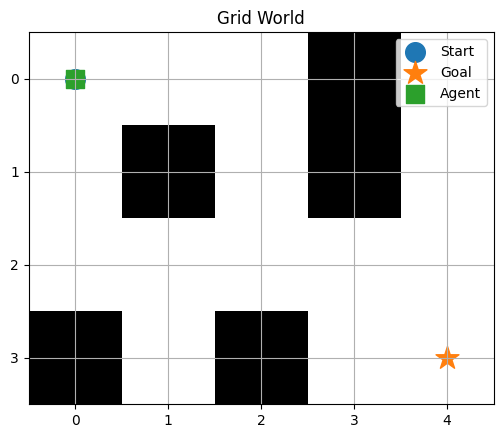

In [ ]:
def visualize_grid(env, title="Grid World"):
    plt.figure(figsize=(6, 5))

    plt.imshow(env.grid, cmap="Greys")

    # Start
    plt.scatter(
        env.start[1],
        env.start[0],
        marker="o",
        s=200,
        label="Start"
    )

    # Goal
    plt.scatter(
        env.goal[1],
        env.goal[0],
        marker="*",
        s=300,
        label="Goal"
    )

    # Current agent position
    plt.scatter(
        env.position[1],
        env.position[0],
        marker="s",
        s=150,
        label="Agent"
    )

    plt.xticks(range(env.cols))
    plt.yticks(range(env.rows))
    plt.grid(True)
    plt.title(title)
    plt.legend()
    plt.show()


visualize_grid(env)

In [ ]:
class SimpleReflexAgent:
    def __init__(self):
        self.name = "Simple Reflex Agent"

    def choose_action(self, env):
        r, c = env.position

        # Condition-action rules based only on the current position
        possible_actions = ["RIGHT", "DOWN", "LEFT", "UP"]

        for action in possible_actions:

            if action == "RIGHT":
                new_position = (r, c + 1)

            elif action == "DOWN":
                new_position = (r + 1, c)

            elif action == "LEFT":
                new_position = (r, c - 1)

            else:
                new_position = (r - 1, c)

            if env.is_valid(new_position):
                return action

        return None

In [ ]:
simple_agent = SimpleReflexAgent()

env.reset()

action = simple_agent.choose_action(env)

print("Agent:", simple_agent.name)
print("Current position:", env.position)
print("Selected action:", action)

Agent: Simple Reflex Agent
Current position: (0, 0)
Selected action: RIGHT


In [ ]:
env.reset()

print("Starting position:", env.position)

for step in range(5):
    action = simple_agent.choose_action(env)

    if action is None:
        print("No valid action available.")
        break

    env.move(action)

    print(
        f"Step {step + 1}: "
        f"Action = {action}, "
        f"Position = {env.position}"
    )

    if env.reached_goal():
        print("Goal reached!")
        break

Starting position: (0, 0)
Step 1: Action = RIGHT, Position = (0, 1)
Step 2: Action = RIGHT, Position = (0, 2)
Step 3: Action = DOWN, Position = (1, 2)
Step 4: Action = DOWN, Position = (2, 2)
Step 5: Action = RIGHT, Position = (2, 3)


In [ ]:
def get_percept(self):
    r, c = self.position

    neighbors = {
        "UP": (r - 1, c),
        "DOWN": (r + 1, c),
        "LEFT": (r, c - 1),
        "RIGHT": (r, c + 1)
    }

    percept = {}

    for direction, position in neighbors.items():
        percept[direction] = self.is_valid(position)

    return percept


GridWorld.get_percept = get_percept

In [ ]:
env.reset()

print("Current position:", env.position)
print("Current percept:", env.get_percept())

Current position: (0, 0)
Current percept: {'UP': False, 'DOWN': np.True_, 'LEFT': False, 'RIGHT': np.True_}


In [ ]:
class ModelBasedReflexAgent:
    def __init__(self, goal):
        self.name = "Model-Based Reflex Agent"
        self.goal = goal
        self.visited = set()
        self.internal_model = {}

    def reset(self):
        self.visited = set()
        self.internal_model = {}

    def update_model(self, env):
        position = env.position
        percept = env.get_percept()

        self.internal_model[position] = percept
        self.visited.add(position)

    def choose_action(self, env):
        self.update_model(env)

        r, c = env.position
        gr, gc = self.goal

        percept = env.get_percept()

        # Prefer movement toward the goal
        preferred_actions = []

        if gc > c:
            preferred_actions.append("RIGHT")
        elif gc < c:
            preferred_actions.append("LEFT")

        if gr > r:
            preferred_actions.append("DOWN")
        elif gr < r:
            preferred_actions.append("UP")

        # Add remaining directions as alternatives
        for action in ["RIGHT", "DOWN", "LEFT", "UP"]:
            if action not in preferred_actions:
                preferred_actions.append(action)

        # Prefer unvisited valid cells
        for action in preferred_actions:
            if percept[action]:
                dr, dc = {
                    "UP": (-1, 0),
                    "DOWN": (1, 0),
                    "LEFT": (0, -1),
                    "RIGHT": (0, 1)
                }[action]

                new_position = (r + dr, c + dc)

                if new_position not in self.visited:
                    return action

        # If all valid neighboring cells were visited,
        # choose any valid action.
        for action in preferred_actions:
            if percept[action]:
                return action

        return None

In [ ]:
model_agent = ModelBasedReflexAgent(goal)

env.reset()
model_agent.reset()

action = model_agent.choose_action(env)

print("Agent:", model_agent.name)
print("Current position:", env.position)
print("Selected action:", action)
print("Internal model:", model_agent.internal_model)

Agent: Model-Based Reflex Agent
Current position: (0, 0)
Selected action: RIGHT
Internal model: {(0, 0): {'UP': False, 'DOWN': np.True_, 'LEFT': False, 'RIGHT': np.True_}}


In [ ]:
env.reset()
model_agent.reset()

print("Starting position:", env.position)

for step in range(20):
    action = model_agent.choose_action(env)

    if action is None:
        print("No valid action available.")
        break

    env.move(action)

    print(
        f"Step {step + 1}: "
        f"Action = {action}, "
        f"Position = {env.position}"
    )

    if env.reached_goal():
        print("Goal reached!")
        break

Starting position: (0, 0)
Step 1: Action = RIGHT, Position = (0, 1)
Step 2: Action = RIGHT, Position = (0, 2)
Step 3: Action = DOWN, Position = (1, 2)
Step 4: Action = DOWN, Position = (2, 2)
Step 5: Action = RIGHT, Position = (2, 3)
Step 6: Action = RIGHT, Position = (2, 4)
Step 7: Action = DOWN, Position = (3, 4)
Goal reached!


In [ ]:
class GoalBasedAgent:
    def __init__(self, goal):
        self.name = "Goal-Based Agent"
        self.goal = goal
        self.path = []

    def find_shortest_path(self, env):
        start = env.position
        goal = self.goal

        queue = deque([(start, [])])
        visited = {start}

        directions = {
            "UP": (-1, 0),
            "DOWN": (1, 0),
            "LEFT": (0, -1),
            "RIGHT": (0, 1)
        }

        while queue:
            current_position, path = queue.popleft()

            if current_position == goal:
                return path

            r, c = current_position

            for action, (dr, dc) in directions.items():
                new_position = (r + dr, c + dc)

                if (
                    env.is_valid(new_position)
                    and new_position not in visited
                ):
                    visited.add(new_position)
                    queue.append(
                        (new_position, path + [action])
                    )

        return []

    def choose_action(self, env):
        if not self.path:
            self.path = self.find_shortest_path(env)

        if self.path:
            return self.path.pop(0)

        return None

In [ ]:
goal_agent = GoalBasedAgent(goal)

env.reset()

path = goal_agent.find_shortest_path(env)

print("Agent:", goal_agent.name)
print("Start:", env.start)
print("Goal:", env.goal)
print("Shortest path:", path)
print("Number of steps:", len(path))

Agent: Goal-Based Agent
Start: (0, 0)
Goal: (3, 4)
Shortest path: ['DOWN', 'DOWN', 'RIGHT', 'RIGHT', 'RIGHT', 'DOWN', 'RIGHT']
Number of steps: 7


In [ ]:
env.reset()
goal_agent.path = []

print("Starting position:", env.position)

for step in range(20):
    action = goal_agent.choose_action(env)

    if action is None:
        print("No path to goal.")
        break

    env.move(action)

    print(
        f"Step {step + 1}: "
        f"Action = {action}, "
        f"Position = {env.position}"
    )

    if env.reached_goal():
        print("Goal reached!")
        break

Starting position: (0, 0)
Step 1: Action = DOWN, Position = (1, 0)
Step 2: Action = DOWN, Position = (2, 0)
Step 3: Action = RIGHT, Position = (2, 1)
Step 4: Action = RIGHT, Position = (2, 2)
Step 5: Action = RIGHT, Position = (2, 3)
Step 6: Action = DOWN, Position = (3, 3)
Step 7: Action = RIGHT, Position = (3, 4)
Goal reached!


In [ ]:
class UtilityBasedAgent:
    def __init__(self, goal, battery=100):
        self.name = "Utility-Based Agent"
        self.goal = goal
        self.battery = battery
        self.initial_battery = battery
        self.visited = set()

    def reset(self):
        self.battery = self.initial_battery
        self.visited = set()

    def calculate_utility(self, position):
        # Manhattan distance to goal
        distance = abs(position[0] - self.goal[0]) + \
                   abs(position[1] - self.goal[1])

        # Penalize previously visited cells
        visited_penalty = 2 if position in self.visited else 0

        # Utility balances:
        # - shorter distance to goal
        # - remaining battery
        # - avoiding repeated cells
        utility = (
            -distance
            + (self.battery * 0.01)
            - visited_penalty
        )

        return utility

    def choose_action(self, env):
        r, c = env.position

        directions = {
            "UP": (-1, 0),
            "DOWN": (1, 0),
            "LEFT": (0, -1),
            "RIGHT": (0, 1)
        }

        candidates = []

        for action, (dr, dc) in directions.items():
            new_position = (r + dr, c + dc)

            if env.is_valid(new_position):
                utility = self.calculate_utility(new_position)

                candidates.append(
                    (utility, action, new_position)
                )

        if not candidates:
            return None

        best_choice = max(candidates, key=lambda x: x[0])

        return best_choice[1]

In [ ]:
utility_agent = UtilityBasedAgent(goal, battery=100)

env.reset()
utility_agent.reset()

print("Agent:", utility_agent.name)
print("Initial battery:", utility_agent.battery)

r, c = env.position

for action, (dr, dc) in {
    "UP": (-1, 0),
    "DOWN": (1, 0),
    "LEFT": (0, -1),
    "RIGHT": (0, 1)
}.items():

    new_position = (r + dr, c + dc)

    if env.is_valid(new_position):
        utility = utility_agent.calculate_utility(new_position)


        print(
            f"{action}: "
            f"Position = {new_position}, "
            f"Utility = {utility:.2f}"
        )

Agent: Utility-Based Agent
Initial battery: 100
DOWN: Position = (1, 0), Utility = -5.00
RIGHT: Position = (0, 1), Utility = -5.00


In [ ]:
env.reset()
utility_agent = UtilityBasedAgent(goal, battery=100)

print("Starting position:", env.position)
print("Starting battery:", utility_agent.battery)

for step in range(20):

    utility_agent.visited.add(env.position)

    action = utility_agent.choose_action(env)

    if action is None:
        print("No valid action available.")
        break

    env.move(action)
    utility_agent.battery -= 1

    print(
        f"Step {step + 1}: "
        f"Action = {action}, "
        f"Position = {env.position}, "
        f"Battery = {utility_agent.battery}"
    )

    if env.reached_goal():
        print("Goal reached!")
        break

Starting position: (0, 0)
Starting battery: 100
Step 1: Action = DOWN, Position = (1, 0), Battery = 99
Step 2: Action = DOWN, Position = (2, 0), Battery = 98
Step 3: Action = RIGHT, Position = (2, 1), Battery = 97
Step 4: Action = DOWN, Position = (3, 1), Battery = 96
Step 5: Action = UP, Position = (2, 1), Battery = 95
Step 6: Action = RIGHT, Position = (2, 2), Battery = 94
Step 7: Action = RIGHT, Position = (2, 3), Battery = 93
Step 8: Action = DOWN, Position = (3, 3), Battery = 92
Step 9: Action = RIGHT, Position = (3, 4), Battery = 91
Goal reached!


In [ ]:
environments = {
    "Configuration 1 - Simple": [
        [0, 0, 0, 1, 0],
        [0, 1, 0, 1, 0],
        [0, 0, 0, 0, 0],
        [1, 0, 1, 0, 0]
    ],

    "Configuration 2 - Open": [
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0]
    ],

    "Configuration 3 - Moderate": [
        [0, 0, 1, 0, 0],
        [0, 0, 1, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 1, 1, 0, 0]
    ],

    "Configuration 4 - Complex": [
        [0, 0, 1, 0, 0],
        [0, 1, 1, 0, 1],
        [0, 0, 0, 0, 1],
        [1, 0, 1, 0, 0]
    ],

    "Configuration 5 - Challenging": [
        [0, 0, 1, 1, 0],
        [0, 0, 1, 1, 0],
        [1, 0, 0, 0, 0],
        [0, 0, 1, 0, 0]
    ]
}

print("Number of configurations:", len(environments))


Number of configurations: 5


In [ ]:
def evaluate_agent(agent, grid, start, goal, max_steps=50):
    env = GridWorld(grid, start, goal)

    # Reset agent memory/state when available
    if hasattr(agent, "reset"):
        agent.reset()

    steps = 0
    completed = False

    for _ in range(max_steps):
        action = agent.choose_action(env)

        if action is None:
            break

        env.move(action)
        steps += 1

        if env.reached_goal():
            completed = True
            break

    return {
        "Steps": steps,
        "Completed": completed,
        "Completion Rate": 1 if completed else 0
    }

In [ ]:
def create_agents(goal):
    return [
        SimpleReflexAgent(),
        ModelBasedReflexAgent(goal),
        GoalBasedAgent(goal),
        UtilityBasedAgent(goal, battery=100)
    ]

In [ ]:
results = []

for config_name, grid in environments.items():

    agents = create_agents(goal)

    for agent in agents:

        result = evaluate_agent(
            agent,
            grid,
            start,
            goal
        )

        results.append({
            "Configuration": config_name,
            "Agent": agent.name,
            "Steps": result["Steps"],
            "Completed": result["Completed"],
            "Completion Rate": result["Completion Rate"]
        })

results_df = pd.DataFrame(results)

results_df

,Configuration,Agent,Steps,Completed,Completion Rate
0,Configuration 1 - Simple,Simple Reflex Agent,7,True,1
1,Configuration 1 - Simple,Model-Based Reflex Agent,7,True,1
2,Configuration 1 - Simple,Goal-Based Agent,7,True,1
3,Configuration 1 - Simple,Utility-Based Agent,50,False,0
4,Configuration 2 - Open,Simple Reflex Agent,7,True,1
5,Configuration 2 - Open,Model-Based Reflex Agent,7,True,1
6,Configuration 2 - Open,Goal-Based Agent,7,True,1
7,Configuration 2 - Open,Utility-Based Agent,7,True,1
8,Configuration 3 - Moderate,Simple Reflex Agent,7,True,1
9,Configuration 3 - Moderate,Model-Based Reflex Agent,7,True,1


In [ ]:
performance_summary = (
    results_df
    .groupby("Agent")
    .agg(
        Average_Steps=("Steps", "mean"),
        Completion_Rate=("Completion Rate", "mean")
    )
    .reset_index()
)

performance_summary["Completion_Rate"] *= 100

performance_summary

,Agent,Average_Steps,Completion_Rate
0,Goal-Based Agent,7.0,100.0
1,Model-Based Reflex Agent,7.4,100.0
2,Simple Reflex Agent,15.6,80.0
3,Utility-Based Agent,41.4,20.0


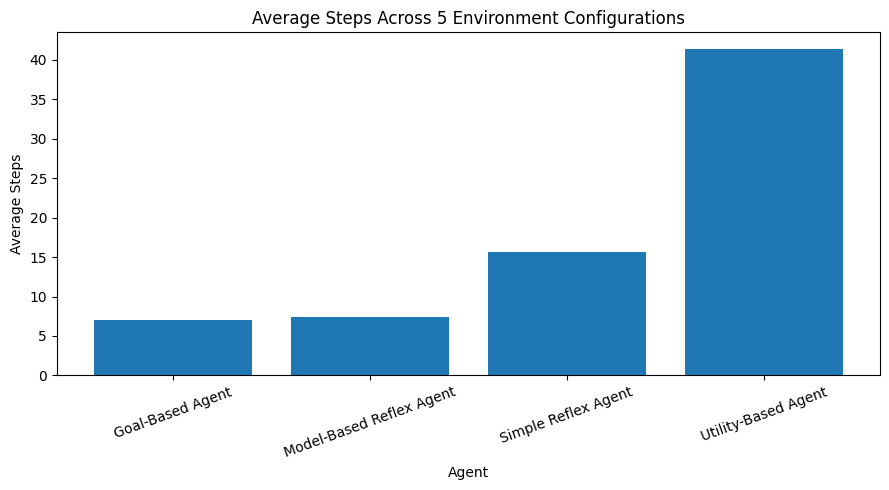

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    performance_summary["Agent"],
    performance_summary["Average_Steps"]
)

plt.xlabel("Agent")
plt.ylabel("Average Steps")
plt.title("Average Steps Across 5 Environment Configurations")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
configuration_comparison = results_df.pivot(
    index="Configuration",
    columns="Agent",
    values="Steps"
)

configuration_comparison

Agent,Goal-Based Agent,Model-Based Reflex Agent,Simple Reflex Agent,Utility-Based Agent
Configuration,,,,
Configuration 1 - Simple,7,7,7,50
Configuration 2 - Open,7,7,7,7
Configuration 3 - Moderate,7,7,7,50
Configuration 4 - Complex,7,9,50,50
Configuration 5 - Challenging,7,7,7,50


In [ ]:
completion_comparison = results_df.pivot(
    index="Configuration",
    columns="Agent",
    values="Completion Rate"
) * 100

completion_comparison

Agent,Goal-Based Agent,Model-Based Reflex Agent,Simple Reflex Agent,Utility-Based Agent
Configuration,,,,
Configuration 1 - Simple,100,100,100,0
Configuration 2 - Open,100,100,100,100
Configuration 3 - Moderate,100,100,100,0
Configuration 4 - Complex,100,100,0,0
Configuration 5 - Challenging,100,100,100,0


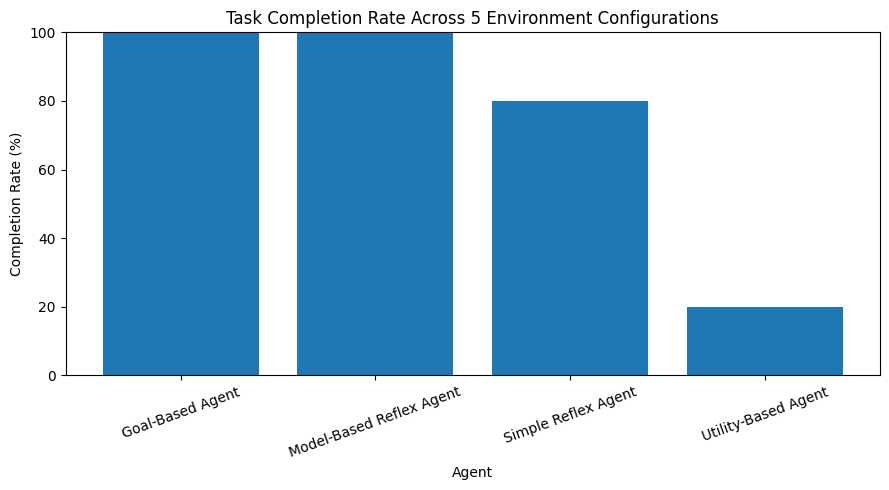

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    performance_summary["Agent"],
    performance_summary["Completion_Rate"]
)

plt.xlabel("Agent")
plt.ylabel("Completion Rate (%)")
plt.title("Task Completion Rate Across 5 Environment Configurations")

plt.ylim(0, 100)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()